In [1]:
!pip install pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 3.0 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/10.9 MB 3.0 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/10.9 MB 2.9 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/10.9 MB 2.7 MB/s eta 0:00:04
   --------- ------------------------------ 2.6/10.9 MB 2.7 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/10.9 MB 2.7 MB/s eta 0:00:03
   -------------- ------------------------- 3.9/10.9 MB 2.8 MB/s eta 0:00:03
   ---------------- ----------------------- 4.5/10.9 MB 2.8 MB/s eta 0:00:03
   ------------------ --------------------- 5.0/10.9 MB 2.8 MB/s eta 0:00:03
   --------------------- ------------------ 5.8/10.9 MB 2.8 MB/s eta 0:00:02
   ----------------------- ---------------- 6.3/10.9 MB 2.8 MB/s eta 0:00:02
   ------------------------- -------------- 6.8/10.9 MB 2.8 MB/s eta 0:00:02
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

df = pd.read_csv(r'C:\Users\MF\Downloads\archive\retail_sales_dataset.csv')
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
df.info()

print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [5]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [6]:
print( df.shape)
print("\nMode of numerical columns:")
print(df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].mode().iloc[0])

(1000, 9)

Mode of numerical columns:
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64


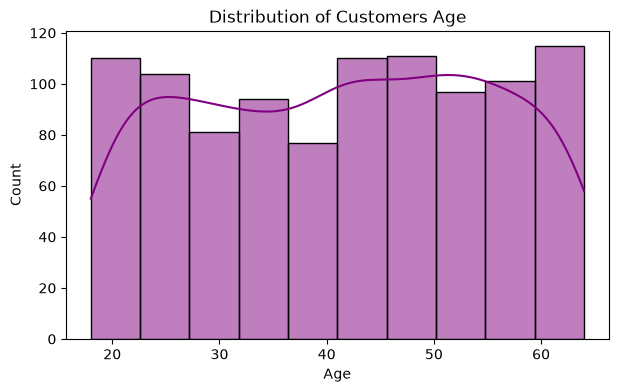

In [ ]:
# 1
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.histplot(df['Age'], bins=10, kde=True, color='purple')
plt.title('Distribution of Customers Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

Observation:- The customer age distribution is quite balanced across all age groups "ranging from 18 to 64 years old" indicating that our retail products appeal to a broad adult demographic without being restricted to a specific age bracket.

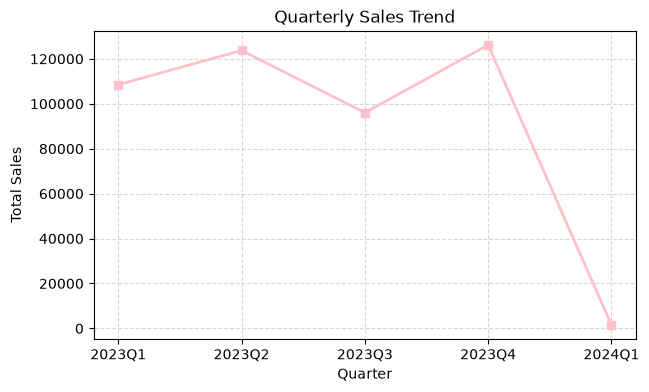

In [ ]:
# 2
df['Date'] = pd.to_datetime(df['Date'])
quarterly_sales = df.groupby(df['Date'].dt.to_period('Q'))['Total Amount'].sum().reset_index()
quarterly_sales['Date'] = quarterly_sales['Date'].astype(str)

plt.figure(figsize=(7, 4))
plt.plot(quarterly_sales['Date'], quarterly_sales['Total Amount'], marker='s', color='pink', linewidth=2)
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Observation:- Sales fluctuated across the quarters showing strong performance in Q2 and Q4 followed by a sharp drop into early 2024 which suggests seasonal buying behavior or a limitation in the dataset's timeframe coverage for late periods

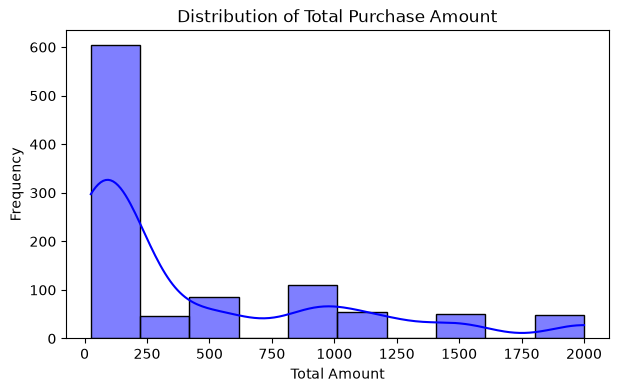

In [ ]:
# 3
plt.figure(figsize=(7, 4))
sns.histplot(df['Total Amount'], bins=10, kde=True, color='Blue')
plt.title('Distribution of Total Purchase Amount')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')
plt.show()

Observation: The total purchase amount is right-skewed with a high frequency of smaller transaction amounts while larger purchases occur less frequently but contribute significantly to overall revenue

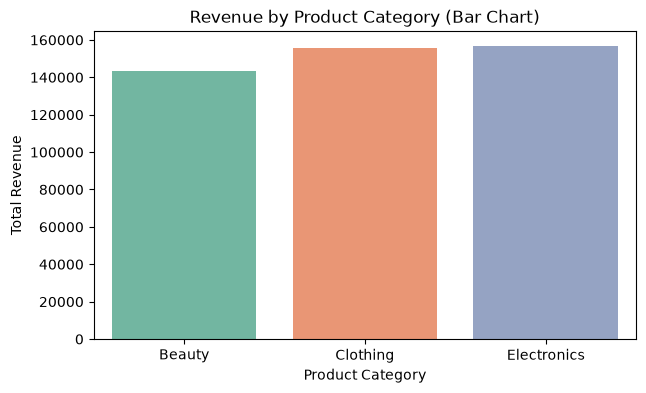

In [ ]:
# 4
cat_sales = df.groupby('Product Category')['Total Amount'].sum().reset_index()

plt.figure(figsize=(7, 4))
sns.barplot(data=cat_sales, x='Product Category', y='Total Amount', palette='Set2', hue='Product Category', legend=False)
plt.title('Revenue by Product Category (Bar Chart)')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.show()

Observation:- All three product categories (Beauty, Clothing, and Electronics) generate very close total revenues with Electronics and Clothing leading slightly showing a healthy diversification of sales across departments.

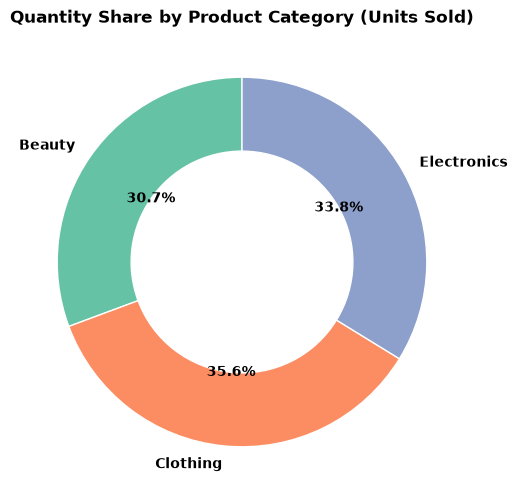

In [ ]:
# 5
category_quantity = df.groupby('Product Category')['Quantity'].sum()

plt.figure(figsize=(6, 6))
plt.pie(category_quantity, labels=category_quantity.index, autopct='%1.1f%%', 
        colors=sns.color_palette('Set2'), startangle=90, 
        wedgeprops=dict(width=0.4, edgecolor='w'),
        textprops={'fontsize': 10, 'weight': 'bold'})

plt.title('Quantity Share by Product Category (Units Sold)', fontsize=12, weight='bold')
plt.show()

Observation: - The donut chart reveals the units sold share per category, showing that Clothing and Electronics account for the highest volume of items purchased by customers

   Gender  Total Amount
0  Female        232840
1    Male        223160


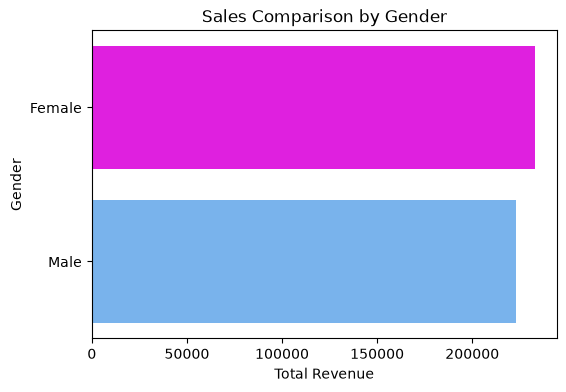

In [ ]:
# 6
gender_sales = df.groupby('Gender')['Total Amount'].sum().reset_index()
print(gender_sales)

plt.figure(figsize=(6, 4))
sns.barplot(data=gender_sales, y='Gender', x='Total Amount', palette=['#ff00ff', '#66b3ff'], hue='Gender', legend=False)

plt.title('Sales Comparison by Gender')
plt.xlabel('Total Revenue')
plt.ylabel('Gender')
plt.show()

Observation:- Female and male customers show a remarkably balanced purchasing behavior with female buyers contributing slightly higher overall revenue compared to males.

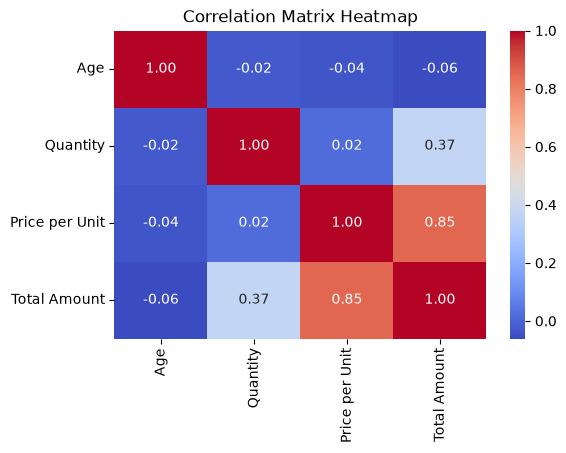

In [ ]:
# 7
plt.figure(figsize=(6, 4))
corr_matrix = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix Heatmap')
plt.show()

Observation: The heatmap shows a strong positive correlation (0.85) between Price per Unit and Total Amount while other variables like Age show near-zero correlation with purchase metrics indicating that age does not heavily influence spending scale.

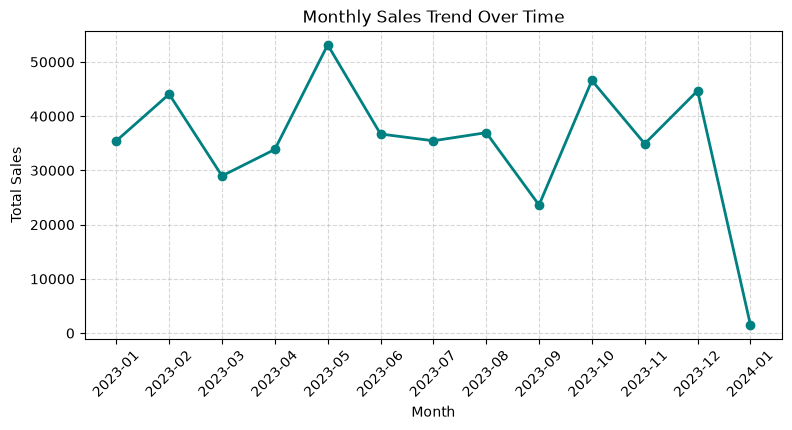

In [ ]:
# 8
df['Date'] = pd.to_datetime(df['Date'])
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Date'].astype(str)

plt.figure(figsize=(9, 4))
plt.plot(monthly_sales['Date'], monthly_sales['Total Amount'], marker='o', color='teal', linewidth=2)

plt.title('Monthly Sales Trend Over Time')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

 The monthly sales trend shows noticeable volatility across the year with a significant peak in May followed by consistent fluctuations and a sharp drop in the final recorded period highlighting the need for targeted promotional campaigns during slower months.

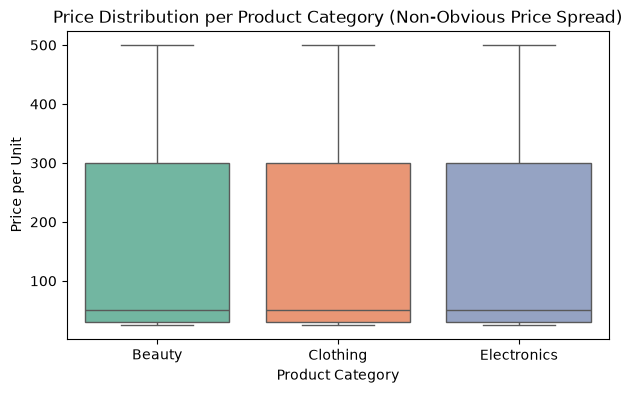

In [ ]:
# 9
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Product Category', y='Price per Unit', palette='Set2', hue='Product Category', legend=False)
plt.title('Price Distribution per Product Category (Non-Obvious Price Spread)')
plt.xlabel('Product Category')
plt.ylabel('Price per Unit')
plt.show()

Observation:- The boxplot demonstrates that the price distribution per unit is uniformly spread across all three product categorie showing identical median prices and interquartile ranges which highlights that pricing strategies are consistent across different product departments

### Conclusion & Business Recommendations
Based on the comprehensive Exploratory Data Analysis (EDA) performed on the retail sales dataset, here are 3 actionable business recommendations:

1. **Capitalize on Top-Performing Categories:** Since Clothing and Electronics lead in both total revenue and units sold, marketing campaigns and inventory stocking should prioritize these high-demand departments.
2. **Leverage Balanced Demographics:** With both genders and a wide range of adult age groups showing active and balanced purchasing patterns, promotional campaigns should remain inclusive rather than targeting a niche demographic.
3. **Targeted Seasonal Promotions:** Noticeable sales fluctuations across quarters indicate seasonal demand peaks; introducing targeted loyalty programs or discount bundles during slower quarters can help maintain steady, year-round revenue flow.